<style>
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2 { color: #003399; }
.jp-RenderedHTMLCommon h3 { color: #1f4e79; }
.note { border-left: 4px solid #003399; padding: 0.4em 0.9em; background: #f4f7fb; }
.warning { border-left: 4px solid #d97706; padding: 0.4em 0.9em; background: #fff8eb; }
details { margin: 0.7em 0; padding: 0.3em 0.7em; background: #f7f7f7; }
</style>

# Практика: зарплаты в вакансиях

У нас есть вакансии специалистов по данным. Для каждой будущей вакансии нужно предсказать среднюю зарплату в тысячах долларов в год.

Главная сложность здесь не в том, чтобы один раз получить маленькую ошибку. Нужно построить проверку, которой можно верить, понять, каким признакам можно доверять, заметить изменение данных со временем и извлечь полезную информацию из текста.

В начале доступны только `train.csv` с ответами и `test.csv` без ответов. Размеченный test откроем один раз в конце, когда решение уже зафиксировано.


## Что понадобится

Понадобится знакомство с `pandas`, линейной регрессией, train/validation/test и RMSE.

Работаем как на олимпиаде: каждое решение принимаем по validation, а не по будущему test.


## Олимпиадный чеклист

В этой практике мы последовательно применим идеи из лекции к одной задаче. Этот список можно потом использовать и в других турах:

- понять объект, target и момент прогноза;
- проверить происхождение признаков;
- выбрать validation, похожую на неизвестный test;
- получить простой ориентир и сравнивать train с validation;
- проверить представление даты и придумать новые признаки;
- следить, какие преобразования обучаются только на train;
- проверить, нужна ли сложной модели регуляризация;
- зафиксировать решение до открытия test.

Перед каждым экспериментом сформулируйте три вещи: какую гипотезу вы проверяете, какой результат будет аргументом в ее пользу и что может сделать такой результат обманчивым. Длинные ответы записывать не нужно, достаточно обсудить идею вслух.

Открывайте подсказку только после собственной попытки. Подсказки помогают с инструментами, но не выбирают решение за вас.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

from scipy.sparse import hstack
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_columns", 30)

warnings.filterwarnings(
    "ignore",
    message=r"(divide by zero|overflow|invalid value) encountered in matmul",
    category=RuntimeWarning,
    module=r"sklearn\.linear_model\._base",
)

TARGET = "salary_k_usd"


## 0. Загружаем данные

Загрузим два файла: размеченный train и будущий test без ответов. Ответы test откроем только в конце.


In [2]:
TRAIN_URL = "https://drive.google.com/uc?export=download&id=1OLBotfoA5oJpS3KyKVpqEWue-lbcqMJ7"
TEST_URL = "https://drive.google.com/uc?export=download&id=17IAX47AY3A67BWzu25D192TyR7PqEieO"

train_full = pd.read_csv(TRAIN_URL, parse_dates=["posting_date"])
test = pd.read_csv(TEST_URL, parse_dates=["posting_date"])

print("train:", train_full.shape)
print("test:", test.shape)


train: (603, 20)
test: (139, 16)


In [3]:
display(train_full.head(3).drop(columns="job_description"))
print(train_full.dtypes)


job_id                              object
posting_date                datetime64[ns]
job_title                           object
job_description                     object
rating                             float64
company_name                        object
location                            object
headquarters                        object
company_size                        object
founded                              int64
ownership_type                      object
industry                            object
sector                              object
revenue                             object
competitors                         object
salary_estimate                     object
salary_floor_k                     float64
salary_ceiling_k                   float64
industry_salary_mean_all           float64
salary_k_usd                       float64
dtype: object


     job_id posting_date                                      job_title  \
0  JOB-0001   2023-01-09                                 Data Scientist   
1  JOB-0002   2023-01-12  Senior Data Scientist Artificial Intelligence   
2  JOB-0003   2023-01-12  Senior Data Scientist Artificial Intelligence   

   rating  company_name      location         headquarters  \
0     4.8  TechProjects  New York, NY  North Brunswick, NJ   
1     3.8          PNNL  Richland, WA         Richland, WA   
2     3.8          PNNL  Richland, WA         Richland, WA   

             company_size  founded     ownership_type     industry  \
0       1 to 50 employees     2011  Company - Private  IT Services   
1  1001 to 5000 employees     1965         Government       Energy   
2  1001 to 5000 employees     1965         Government       Energy   

                         sector                           revenue  \
0        Information Technology          Unknown / Non-Applicable   
1  Oil, Gas, Energy & Utilities

Одна строка соответствует одной вакансии. Прогноз строится в день публикации, поэтому в модель можно передавать только информацию, известную в этот момент.

Target `salary_k_usd` есть только в train. Это средняя годовая зарплата в тысячах долларов.


## Проверка 1. Одинаково ли устроены train и test

В олимпиадной задаче сначала сравнивают сами таблицы. Target должен быть только в train. Найдите остальные столбцы, которые есть лишь в одной из выборок.

<details>
<summary>Подсказка</summary>

Столбцы можно превратить в `set` и вычесть одно множество из другого.

</details>


In [4]:
train_only_columns = sorted(
    set(train_full.columns) - set(test.columns) - {TARGET}
)
test_only_columns = sorted(set(test.columns) - set(train_full.columns))

print("Только в train:", train_only_columns)
print("Только в test:", test_only_columns)


Только в train: ['salary_ceiling_k', 'salary_estimate', 'salary_floor_k']
Только в test: []


### Разбор результата

Кроме target, только в train находятся `salary_estimate`, `salary_floor_k` и `salary_ceiling_k`. Финальная модель не сможет получить эти значения для test. Названия также подсказывают, что столбцы непосредственно описывают зарплату, которую требуется предсказать.


### Сравнение числовых распределений

Одинаковые названия столбцов еще не означают одинаковые данные. Для каждого общего числового признака сравните среднее и стандартное отклонение. Разность средних разделите на типичный масштаб признака.

<details>
<summary>Подсказка</summary>

Пригодятся [`select_dtypes`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.select_dtypes.html), [`mean`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html), [`std`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html) и `pd.DataFrame`.

В знаменателе можно использовать среднее двух стандартных отклонений. Добавьте небольшое число, чтобы не делить на ноль.

</details>


In [5]:
common_columns = train_full.columns.intersection(test.columns)
common_numeric = (
    train_full[common_columns]
    .select_dtypes(include="number")
    .columns
    .tolist()
)

numeric_shift = pd.DataFrame(
    {
        "train_mean": train_full[common_numeric].mean(),
        "test_mean": test[common_numeric].mean(),
        "train_std": train_full[common_numeric].std(),
        "test_std": test[common_numeric].std(),
    }
)
typical_scale = (
    numeric_shift["train_std"] + numeric_shift["test_std"]
) / 2
numeric_shift["standardized_difference"] = (
    (numeric_shift["train_mean"] - numeric_shift["test_mean"]).abs()
    / (typical_scale + 1e-9)
)

display(
    numeric_shift.sort_values(
        "standardized_difference",
        ascending=False,
    )
)


                           train_mean    test_mean   train_std    test_std  \
rating                       3.647264     3.876978    0.753180    1.021956   
industry_salary_mean_all    99.834942    99.563453   15.732331   15.387350   
founded                   1838.164179  1832.776978  493.642534  514.067540   

                          standardized_difference  
rating                                   0.258814  
industry_salary_mean_all                 0.017448  
founded                                  0.010692  

### Сдвиг категориальных распределений

Для категорий сравним все доли сразу. Половина суммы абсолютных различий долей называется total variation distance:

$$
\mathrm{TVD}(p,q)=\frac{1}{2}\sum_k |p_k-q_k|.
$$

TVD равна `0` для одинаковых распределений и `1`, если множества значений не пересекаются. Посчитайте ее для общих категориальных признаков, где не больше ста разных значений.

<details>
<summary>Подсказка</summary>

Для каждого столбца соедините два результата `value_counts(normalize=True)` через `pd.concat(..., axis=1)`, заполните отсутствующие доли нулями и просуммируйте модуль разности.

</details>


In [6]:
categorical_shift = []
for feature in common_columns:
    if train_full[feature].dtype != "object":
        continue
    if max(train_full[feature].nunique(), test[feature].nunique()) > 100:
        continue

    shares = pd.concat(
        [
            train_full[feature].value_counts(normalize=True),
            test[feature].value_counts(normalize=True),
        ],
        axis=1,
    ).fillna(0)
    tvd = 0.5 * (shares.iloc[:, 0] - shares.iloc[:, 1]).abs().sum()
    categorical_shift.append({"feature": feature, "tvd": tvd})

categorical_shift = pd.DataFrame(categorical_shift)
display(categorical_shift.sort_values("tvd", ascending=False))


          feature       tvd
0    company_size  0.324862
2        industry  0.296563
3          sector  0.183817
4         revenue  0.169333
1  ownership_type  0.119689

### Распределения отдельных признаков

Две таблицы показывают кандидатов, но форму распределения лучше увидеть. Постройте гистограммы `rating` и сравните доли значений `company_size`: это лидеры среди простых числовых и категориальных проверок.

<details>
<summary>Подсказка</summary>

Для числового признака подойдет [`hist`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html). Для категориального используйте [`value_counts(normalize=True)`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html), соедините две серии через `pd.concat` и вызовите `.plot.bar()`.

</details>


                            train      test
company_size                               
Unknown                  0.013267  0.338129
501 to 1000 employees    0.179104  0.158273
1001 to 5000 employees   0.195688  0.122302
51 to 200 employees      0.119403  0.115108
201 to 500 employees     0.154229  0.100719
10000+ employees         0.185738  0.086331
5001 to 10000 employees  0.101161  0.071942
1 to 50 employees        0.049751  0.007194
-1                       0.001658  0.000000

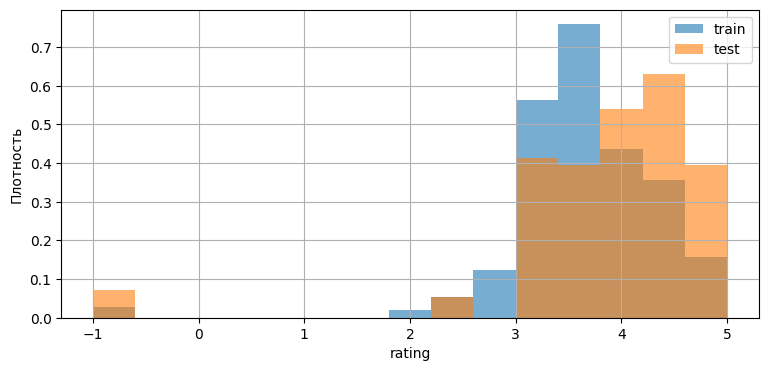

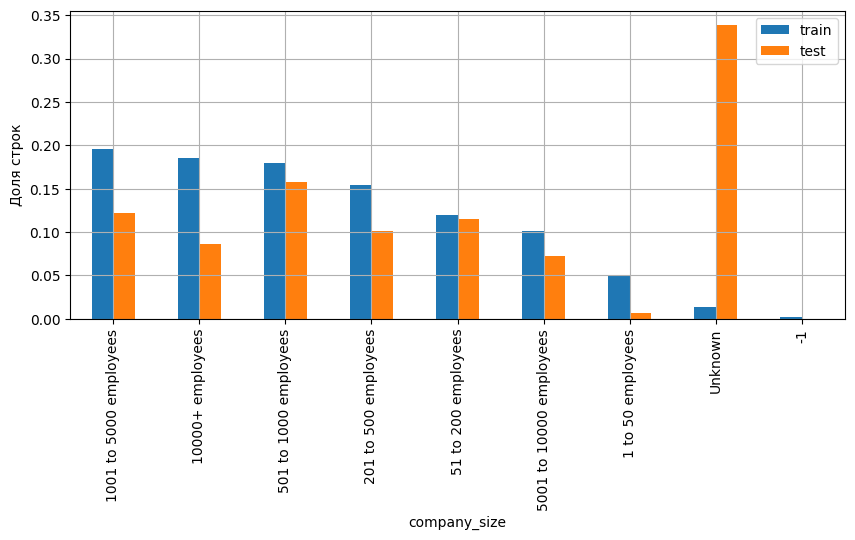

In [7]:
plt.hist(train_full["rating"], bins=15, alpha=0.6, density=True, label="train")
plt.hist(test["rating"], bins=15, alpha=0.6, density=True, label="test")
plt.xlabel("rating")
plt.ylabel("Плотность")
plt.legend()
plt.show()

company_size_shift = pd.concat(
    {
        "train": train_full["company_size"].value_counts(normalize=True),
        "test": test["company_size"].value_counts(normalize=True),
    },
    axis=1,
).fillna(0)

display(company_size_shift.sort_values("test", ascending=False))
company_size_shift.plot.bar(figsize=(10, 4))
plt.ylabel("Доля строк")
plt.show()


### Вывод и следующая проверка

В test выше средний `rating` и намного чаще встречается `company_size="Unknown"`. Это уже два сигнала сдвига, но ручной просмотр охватывает лишь выбранные признаки. Следующая гипотеза: если различий достаточно, классификатор источника получит ROC AUC заметно выше `0.5`. Именно это проверяет следующий эксперимент.


### Модель «train или test»

Ручные графики показывают только выбранные признаки. Более общий способ поиска сдвига: объединить таблицы и обучить классификатор предсказывать источник строки.

Прямой признак даты не используем: test целиком находится в будущем, и по дате задача решалась бы без анализа остальных различий. Зато добавим длину описания, чтобы модель могла заметить простой сдвиг в текстах.

ROC AUC около `0.5` означает, что выборки трудно отличить. Чем ближе AUC к `1`, тем заметнее сдвиг.

Масштабирование и one-hot должны обучаться заново внутри каждого фолда. Для этого соберем преобразования и модель в `Pipeline`.

<details>
<summary>Подсказка</summary>

Документация: [`ColumnTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [`cross_val_score`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html) и [`StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html).

Добавьте метку `is_test`: `0` для train и `1` для test. В `ColumnTransformer` числа передайте в `StandardScaler`, а категории в `OneHotEncoder`.

</details>

<div class="note">В соревновании такая проверка возможна, потому что признаки test уже даны. В реальном сервисе будущие объекты часто еще недоступны.</div>


In [8]:
source_train = train_full.drop(columns=[TARGET] + train_only_columns).copy()
source_train["is_test"] = 0
source_test = test.copy()
source_test["is_test"] = 1
source_data = pd.concat([source_train, source_test], ignore_index=True)
source_data["description_length"] = source_data["job_description"].fillna("").str.len()

SOURCE_NUMERIC = ["rating", "founded", "description_length"]
SOURCE_CATEGORICAL = ["company_size", "ownership_type", "industry", "sector"]
y_source = source_data["is_test"]


In [9]:
source_preprocessor = ColumnTransformer(
    [
        ("numeric", StandardScaler(), SOURCE_NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), SOURCE_CATEGORICAL),
    ]
)
source_model = Pipeline(
    [
        ("preprocessor", source_preprocessor),
        ("model", LogisticRegression(C=0.3, max_iter=2000, solver="liblinear")),
    ]
)


In [10]:
source_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
source_auc = cross_val_score(
    source_model,
    source_data,
    y_source,
    scoring="roc_auc",
    cv=source_cv,
)
print("AUC по фолдам:", np.round(source_auc, 3))
print("Средний AUC:", round(source_auc.mean(), 3))

_ = source_model.fit(source_data, y_source)


AUC по фолдам: [0.756 0.724 0.697 0.735 0.801]
Средний AUC: 0.743


In [11]:
fitted_preprocessor = source_model.named_steps["preprocessor"]
fitted_classifier = source_model.named_steps["model"]
source_feature_names = np.concatenate(
    [
        np.array(SOURCE_NUMERIC, dtype=object),
        fitted_preprocessor.named_transformers_["categorical"].get_feature_names_out(SOURCE_CATEGORICAL),
    ]
)
source_coefficients = pd.DataFrame(
    {"feature": source_feature_names, "coefficient": fitted_classifier.coef_[0]}
)
print("Сильнее связаны с test")
display(source_coefficients.nlargest(8, "coefficient"))
print("Сильнее связаны с train")
display(source_coefficients.nsmallest(8, "coefficient"))


Сильнее связаны с test
Сильнее связаны с train


                                          feature  coefficient
11                           company_size_Unknown     2.429711
47         industry_Food & Beverage Manufacturing     0.592476
48                              industry_Gambling     0.588562
87        sector_Arts, Entertainment & Recreation     0.588562
18          ownership_type_Nonprofit Organization     0.474566
0                                          rating     0.414231
27  industry_Architectural & Engineering Services     0.373036
33               industry_Colleges & Universities     0.342591

                                     feature  coefficient
15           ownership_type_Company - Public    -0.795377
5              company_size_10000+ employees    -0.752504
4             company_size_1 to 50 employees    -0.615983
14          ownership_type_Company - Private    -0.530467
93                            sector_Finance    -0.528002
38  industry_Consumer Products Manufacturing    -0.508470
6        company_size_1001 to 5000 employees    -0.504929
7          company_size_201 to 500 employees    -0.444637

### Разбор результата

Средний ROC AUC около `0.75`, поэтому train и test различаются даже без даты. `company_size` получает TVD около `0.32`, `industry` около `0.30`. Самый заметный отдельный сигнал test: значение `Unknown` в `company_size`. Оно встречается примерно в трети test и лишь в нескольких процентах train. Средний `rating` в test также выше.

Классификатор не доказывает, что конкретный признак вреден для прогноза зарплаты. Он показывает, что случайная validation из train не воспроизведет часть будущего сдвига. Поэтому временное разбиение и отдельный анализ test необходимы.


## Проверка 2. Как признаки связаны с ответом

Начнем с числовых корреляций. Будущая validation начинается 1 февраля 2025 года, поэтому для первичного анализа используйте только более ранние строки. Найдите корреляцию каждого числового столбца с `salary_k_usd` и отсортируйте значения по убыванию модуля.

<details>
<summary>Подсказка</summary>

Сначала выберите числовые столбцы методом [`select_dtypes`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.select_dtypes.html). Затем пригодятся [`corr`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html), `abs` и [`sort_values`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html).

</details>


In [12]:
correlation_data = train_full[
    train_full["posting_date"] < pd.Timestamp("2025-02-01")
].copy()

numeric_columns = correlation_data.select_dtypes(include="number").columns
target_correlations = correlation_data[numeric_columns].corr()[TARGET]
target_correlations = target_correlations.drop(TARGET)

display(
    target_correlations
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .to_frame("correlation_with_target")
)


                          correlation_with_target
salary_floor_k                           0.993538
salary_ceiling_k                         0.993449
industry_salary_mean_all                 0.514919
rating                                   0.074719
founded                                 -0.042334

Корреляция дала кандидатов для проверки, но не ответ. Сначала разберем признаки, которых нет в test. Проверьте, насколько середина двух числовых границ близка к target.

<details>
<summary>Подсказка</summary>

Создайте `midpoint_k` как полусумму `salary_floor_k` и `salary_ceiling_k`. Для проверки пригодятся корреляция, максимальная абсолютная ошибка и диаграмма рассеяния.

</details>


Максимальное отличие от середины вилки: 0.04


  salary_estimate  salary_floor_k  salary_ceiling_k  salary_k_usd  midpoint_k
0     $109K-$137K           109.4             137.1        123.23      123.25
1       $46K-$74K            45.9              73.6         59.76       59.75
2       $53K-$86K            53.0              85.7         69.36       69.35
3       $62K-$83K            62.4              83.2         72.81       72.80
4     $116K-$144K           115.7             144.4        130.02      130.05

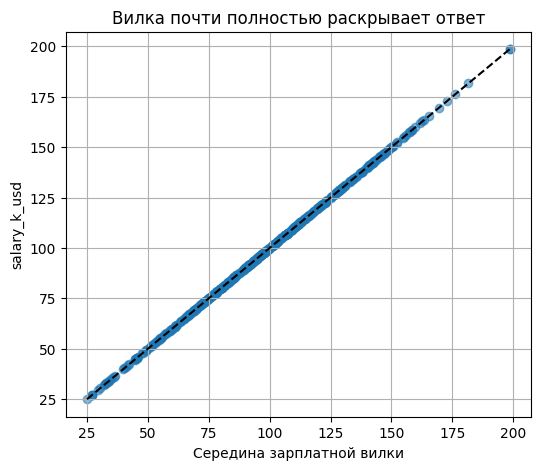

In [13]:
salary_audit = correlation_data[
    [
        "salary_estimate",
        "salary_floor_k",
        "salary_ceiling_k",
        TARGET,
    ]
].copy()
salary_audit["midpoint_k"] = (
    salary_audit["salary_floor_k"]
    + salary_audit["salary_ceiling_k"]
) / 2

display(salary_audit.head())

left = min(salary_audit["midpoint_k"].min(), salary_audit[TARGET].min())
right = max(salary_audit["midpoint_k"].max(), salary_audit[TARGET].max())

plt.figure(figsize=(6, 5))
plt.scatter(salary_audit["midpoint_k"], salary_audit[TARGET], alpha=0.55)
plt.plot([left, right], [left, right], color="black", linestyle="--")
plt.xlabel("Середина зарплатной вилки")
plt.ylabel("salary_k_usd")
plt.title("Вилка почти полностью раскрывает ответ")
plt.show()

midpoint_error = (salary_audit["midpoint_k"] - salary_audit[TARGET]).abs()
print("Максимальное отличие от середины вилки:", round(midpoint_error.max(), 3))


Как объяснить почти идеальную диагональ? Как `salary_estimate` связан с двумя числовыми границами? Что произойдет с validation, если оставить хотя бы одно из этих представлений ответа?

Теперь проверьте `industry_salary_mean_all`. Восстановите среднюю зарплату каждой отрасли по всему train и сравните ее с готовым столбцом.

<details>
<summary>Подсказка</summary>

Пригодится `train_full.groupby("industry")[TARGET].transform("mean")`. Метод `transform` вернет значение для каждой исходной строки.

</details>


Максимальное отличие: 0.005


                    industry  industry_salary_mean_all  salary_k_usd  \
174  Consumer Product Rental                     85.02         91.77   
437                  Lending                     86.82         90.71   
78                   Lending                     86.82        117.87   
175  Consumer Product Rental                     85.02         78.28   
354                  Lending                     86.82         49.08   
355                  Lending                     86.82         66.16   
399                  Lending                     86.82         88.89   
400                  Lending                     86.82         73.27   

     reconstructed_industry_mean  absolute_difference  
174                       85.025                0.005  
437                       86.825                0.005  
78                        86.825                0.005  
175                       85.025                0.005  
354                       86.825                0.005  
355            

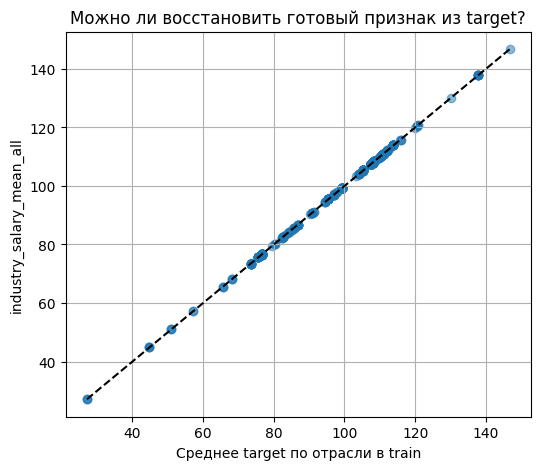

In [14]:
industry_audit = train_full[
    ["industry", "industry_salary_mean_all", TARGET]

].copy()
industry_audit["reconstructed_industry_mean"] = (
    train_full.groupby("industry")[TARGET].transform("mean")
)
industry_audit["absolute_difference"] = (
    industry_audit["industry_salary_mean_all"]
    - industry_audit["reconstructed_industry_mean"]
).abs()

print(
    "Максимальное отличие:",
    round(industry_audit["absolute_difference"].max(), 3),
)
display(
    industry_audit
    .sort_values("absolute_difference", ascending=False)
    .head(8)
)

plt.figure(figsize=(6, 5))
plt.scatter(
    industry_audit["reconstructed_industry_mean"],
    industry_audit["industry_salary_mean_all"],
    alpha=0.5,
)
left = min(
    industry_audit["reconstructed_industry_mean"].min(),
    industry_audit["industry_salary_mean_all"].min(),
)
right = max(
    industry_audit["reconstructed_industry_mean"].max(),
    industry_audit["industry_salary_mean_all"].max(),
)
plt.plot([left, right], [left, right], color="black", linestyle="--")
plt.xlabel("Среднее target по отрасли в train")
plt.ylabel("industry_salary_mean_all")
plt.title("Можно ли восстановить готовый признак из target?")
plt.show()


Вопросы:

1. Что означает почти нулевое отличие восстановленного среднего от готового столбца?
2. Почему использование такого столбца в validation дает модели информацию об ответах validation?
3. Можно ли исправить среднее по отрасли, если считать его только по прошлым вакансиям?
4. Почему высокая корреляция сама по себе не является причиной удалить признак?

Посмотрите также на текстовые столбцы: числовая таблица корреляций их не показывает.


In [15]:
DROP_COLUMNS = [
    "salary_floor_k",
    "salary_ceiling_k",
    "salary_estimate",
    "industry_salary_mean_all",
]

train_clean = train_full.drop(columns=DROP_COLUMNS)
test_clean = test.drop(columns=DROP_COLUMNS, errors="ignore")


In [16]:
assert TARGET in train_clean.columns
assert TARGET not in test_clean.columns
assert not set(DROP_COLUMNS) & set(train_clean.columns)
assert list(train_clean.drop(columns=TARGET).columns) == list(test_clean.columns)

print("После удаления:", train_clean.shape, test_clean.shape)


После удаления: (603, 16) (139, 15)


### Разбор решения

`salary_floor_k` и `salary_ceiling_k` построены вокруг готового ответа. Их середина отличается от `salary_k_usd` не более чем на `0.04`. `salary_estimate` содержит те же две границы в виде строки. Кроме того, этих признаков нет в test. Оставлять их в модели нельзя.

`industry_salary_mean_all` почти точно восстанавливается как среднее target по отрасли на всем train. Поэтому готовое значение для строк validation уже использует их ответы. Саму идею среднего по отрасли использовать можно, но признак нужно пересчитать: для validation только по `train_part`, а для test по всему доступному train. В основном маршруте готовый столбец удаляется, а корректная версия остается заданием со звездочкой.

Высокая корреляция не является определением утечки. Например, дата может сильно коррелировать с зарплатой и при этом быть известна в момент прогноза. Решение принимается по происхождению признака, а корреляция лишь показывает, что стоит проверить в первую очередь.


## Проверка 3. Как устроен неизвестный test

Посмотрите на периоды train и test. До кода решите, чем validation должна отличаться от train, чтобы ее результат что-то говорил о будущем test.


In [17]:
print("train:", train_clean["posting_date"].min(), "-", train_clean["posting_date"].max())
print("test:", test_clean["posting_date"].min(), "-", test_clean["posting_date"].max())


train: 2023-01-09 00:00:00 - 2025-06-30 00:00:00
test: 2025-07-03 00:00:00 - 2025-12-30 00:00:00


Test целиком находится в будущем относительно train. Поэтому validation тоже должна быть последним непрерывным отрезком времени: вакансии с 1 февраля по 30 июня 2025 года. Более ранние строки останутся в train.

Отсортируйте таблицу по дате и выполните такое разбиение.

<details>
<summary>Подсказка</summary>

Пригодятся [`sort_values`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html), `pd.Timestamp` и фильтрация вида `table[table["date"] < border]`.

</details>


In [18]:
train_clean = train_clean.sort_values("posting_date").reset_index(drop=True)

validation_start = pd.Timestamp("2025-02-01")
train_part = train_clean[train_clean["posting_date"] < validation_start].copy()
validation_part = train_clean[train_clean["posting_date"] >= validation_start].copy()


In [19]:
assert len(train_part) + len(validation_part) == len(train_clean)
assert train_part["posting_date"].max() < validation_part["posting_date"].min()
assert train_part[TARGET].notna().all()
assert validation_part[TARGET].notna().all()

print("train:", train_part.shape, train_part["posting_date"].min(), train_part["posting_date"].max())
print("validation:", validation_part.shape, validation_part["posting_date"].min(), validation_part["posting_date"].max())


train: (505, 16) 2023-01-09 00:00:00 2025-01-28 00:00:00
validation: (98, 16) 2025-02-06 00:00:00 2025-06-30 00:00:00


### Вывод и ограничение

Train содержит `505` ранних строк, validation `98` более поздних. Разбиение воспроизводит перенос во времени и не смешивает будущее с прошлым. Оно пока не воспроизводит изменение источника, найденное классификатором train/test. Поэтому позже отдельно проверим признаки, по которым выборки различаются.


## Проверка 4. Первый честный ориентир

Соберем линейную модель на нескольких числовых и категориальных признаках. Числовые признаки стандартизируем, а категории представим с помощью one-hot кодирования.

Все преобразования обучаются только на train. Validation получает уже найденные средние, масштабы и категории.


In [20]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def fit_tabular_encoder(table, numeric_features, categorical_features):
    scaler = StandardScaler()
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)

    numeric = scaler.fit_transform(table[numeric_features])
    categorical = encoder.fit_transform(table[categorical_features].astype(str))
    matrix = hstack([numeric, categorical], format="csr")

    state = {
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "scaler": scaler,
        "encoder": encoder,
    }
    return matrix, state


In [21]:
def transform_tabular(table, state):
    numeric = state["scaler"].transform(table[state["numeric_features"]])
    categorical = state["encoder"].transform(
        table[state["categorical_features"]].astype(str)
    )
    return hstack([numeric, categorical], format="csr")


def evaluate_tabular(train_table, validation_table, numeric_features, categorical_features, alpha=10):
    X_train, state = fit_tabular_encoder(
        train_table, numeric_features, categorical_features
    )
    X_validation = transform_tabular(validation_table, state)

    model = Ridge(alpha=alpha, solver="lsqr")
    model.fit(X_train, train_table[TARGET])

    return {
        "train_rmse": rmse(train_table[TARGET], model.predict(X_train)),
        "validation_rmse": rmse(
            validation_table[TARGET], model.predict(X_validation)
        ),
        "model": model,
        "state": state,
        "X_train": X_train,
        "X_validation": X_validation,
    }


Для первого ориентира возьмем небольшой общий набор признаков. `job_id`, дату и описание пока не используем. Модель стандартизирует числа и кодирует категории с помощью one-hot.


In [22]:
BASE_NUMERIC = ["rating"]
BASE_CATEGORICAL = [
    "job_title",
    "industry",
    "sector",
    "company_size",
    "ownership_type",
    "location",
]

baseline = evaluate_tabular(
    train_part,
    validation_part,
    BASE_NUMERIC,
    BASE_CATEGORICAL,
)

print("train RMSE:", round(baseline["train_rmse"], 3))
print("validation RMSE:", round(baseline["validation_rmse"], 3))


train RMSE: 19.894
validation RMSE: 35.715


### Вывод и решение

Базовая модель получает train RMSE `19.894` и validation RMSE `35.715`. Большой разрыв показывает, что перенос в более поздний период намного сложнее подгонки под знакомые данные. Эти числа становятся точкой отсчета: новый признак имеет смысл оставлять только после сравнения на той же временной validation.


## Идея 1. Как представить дату

Средняя зарплата по месяцам показывает форму временной зависимости до обучения модели. Ячейка ниже считает среднее только на `train_part`.

До запуска предположите, какую форму зависимости от времени вообще может увидеть линейная модель.

<details>
<summary>Подсказка</summary>

Из даты можно получить месяц вызовом `table["posting_date"].dt.to_period("M")`. Затем пригодятся `groupby`, `mean` и `plot`.

</details>


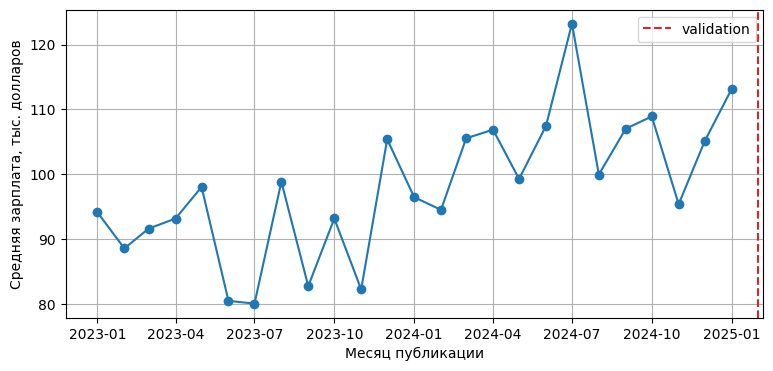

In [23]:
monthly_salary = (
    train_part
    .assign(month=train_part["posting_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month", as_index=False)[TARGET]
    .mean()
)

plt.plot(monthly_salary["month"], monthly_salary[TARGET], marker="o")
plt.axvline(pd.Timestamp("2025-02-01"), color="tab:red", linestyle="--", label="validation")
plt.ylabel("Средняя зарплата, тыс. долларов")
plt.xlabel("Месяц публикации")
plt.legend()
plt.show()


Посмотрите на график и назовите хотя бы две разные закономерности, которые могут быть связаны с датой. Затем решите, достаточно ли для них одного возрастающего числа.

Запишем дату одним числом: количеством дней с 1 января 2023 года. До запуска предположите результат, затем сравните его с базовой моделью.

<details>
<summary>Подсказка</summary>

Из столбца с датой можно вычесть `pd.Timestamp("2023-01-01")`, а затем взять число дней через `.dt.days`.

</details>


In [24]:
train_with_date = train_part.copy()
validation_with_date = validation_part.copy()

start_date = pd.Timestamp("2023-01-01")
train_with_date["date_number"] = (
    train_with_date["posting_date"] - start_date
).dt.days
validation_with_date["date_number"] = (
    validation_with_date["posting_date"] - start_date
).dt.days

raw_date_result = evaluate_tabular(
    train_with_date,
    validation_with_date,
    BASE_NUMERIC + ["date_number"],
    BASE_CATEGORICAL,
)

print("Без даты:", round(baseline["validation_rmse"], 3))
print("Дата одним числом:", round(raw_date_result["validation_rmse"], 3))


Без даты: 35.715
Дата одним числом: 35.071


### Разбор результата

Дата одним числом не дала убедительного улучшения. Это согласуется с графиком: один линейный наклон плохо описывает зависимость, которая меняет направление. Дата здесь не утечка, потому что известна заранее.


### Циклическая часть даты

Какую идею из лекции можно применить, если часть зависимости повторяется по календарю? Вспомните, почему обычный номер месяца не передает соседство декабря и января.

Для проверки используем пару циклических признаков:

Разместим месяцы на окружности:

$$
\text{month\_sin}=\sin\left(2\pi\frac{m-1}{12}\right),\qquad
\text{month\_cos}=\cos\left(2\pi\frac{m-1}{12}\right).
$$

Одного синуса недостаточно: одинаковому значению соответствуют две разные точки окружности. Пара синуса и косинуса задает положение месяца однозначно.


In [25]:
train_with_cycle = train_part.copy()
validation_with_cycle = validation_part.copy()

for table in [train_with_cycle, validation_with_cycle]:
    month = table["posting_date"].dt.month
    angle = 2 * np.pi * (month - 1) / 12
    table["month_sin"] = np.sin(angle)
    table["month_cos"] = np.cos(angle)

cyclic_result = evaluate_tabular(
    train_with_cycle,
    validation_with_cycle,
    BASE_NUMERIC + ["month_sin", "month_cos"],
    BASE_CATEGORICAL,
)

date_results = pd.DataFrame(
    {
        "features": ["без даты", "дата одним числом", "sin/cos месяца"],
        "validation_rmse": [
            baseline["validation_rmse"],
            raw_date_result["validation_rmse"],
            cyclic_result["validation_rmse"],
        ],
    }
)
display(date_results.sort_values("validation_rmse"))


            features  validation_rmse
1  дата одним числом        35.070775
2     sin/cos месяца        35.149210
0           без даты        35.714899

Сравните три строки таблицы. Какая гипотеза о дате получила поддержку, а какая пока нет? Не делайте общий вывод «дата полезна» или «дата бесполезна»: разные представления проверяют разные идеи.


### Разбор результата

`sin/cos` дали RMSE `35.149`: это лучше модели без даты (`35.715`), но немного хуже одного возрастающего числа (`35.071`). Значит, годовая цикличность в данных есть, но сама по себе она не описывает главный временной сдвиг. Результат не опровергает идею циклического кодирования: он показывает, что одной сезонности здесь недостаточно.


### Два наклона вместо одного

Вернитесь к графику. Какие новые числа можно получить из даты, чтобы линейная модель могла вести себя по-разному до и после заметного изменения?

<details>
<summary>Открыть один вариант конструкции</summary>

На графике изменение начинается примерно в ноябре 2024 года. Введем два признака:

$$
\text{month\_index}=0,1,2,\ldots
$$

$$
\text{months\_after\_turn}=\max(\text{month\_index}-22,0).
$$

До разворота второй признак равен нулю. После разворота он растет, поэтому модель может выучить новый наклон. Это нелинейное преобразование даты, но сама модель остается линейной по созданным признакам.

</details>

<details>
<summary>Подсказка</summary>

Непрерывный номер месяца можно получить так: `(year - 2023) * 12 + month - 1`. Положительную часть разности удобно взять методом `.clip(lower=0)`.

</details>


In [26]:
train_with_trend = train_with_cycle.copy()
validation_with_trend = validation_with_cycle.copy()

for table in [train_with_trend, validation_with_trend]:
    table["month_index"] = (
        (table["posting_date"].dt.year - 2023) * 12
        + table["posting_date"].dt.month
        - 1
    )
    table["months_after_turn"] = (table["month_index"] - 22).clip(lower=0)

DATE_FEATURES = [
    "month_sin",
    "month_cos",
    "month_index",
    "months_after_turn",
]

trend_only_result = evaluate_tabular(
    train_with_trend,
    validation_with_trend,
    BASE_NUMERIC + ["month_index", "months_after_turn"],
    BASE_CATEGORICAL,
)
trend_result = evaluate_tabular(
    train_with_trend,
    validation_with_trend,
    BASE_NUMERIC + DATE_FEATURES,
    BASE_CATEGORICAL,
)

date_ablation = pd.DataFrame(
    {
        "date_features": [
            "только sin/cos",
            "только два наклона",
            "sin/cos и два наклона",
        ],
        "validation_rmse": [
            cyclic_result["validation_rmse"],
            trend_only_result["validation_rmse"],
            trend_result["validation_rmse"],
        ],
    }
)
display(date_ablation.sort_values("validation_rmse"))


           date_features  validation_rmse
2  sin/cos и два наклона        33.982146
0         только sin/cos        35.149210
1     только два наклона        35.440038

Сравните результат с циклическими признаками. Что именно добавила новая конструкция? Небольшое изменение одной validation еще не доказывает, что прием всегда полезен. На других данных точку изменения придется заново обосновать и проверить.


### Разбор результата

По отдельности сезонность дает RMSE `35.149`, а два наклона `35.440`. Вместе они дают `33.982`. Значит, признаки описывают разные части зависимости: `sin/cos` отвечают за повторение по календарю, а `month_index` и `months_after_turn` за изменение общего уровня и разворот.

В финальный набор `DATE_FEATURES` входят все четыре признака, потому что лучший результат получен именно их сочетанием. Точка разворота выбрана по ранней истории, а не по validation или test. В другой задаче ее придется заново обосновать на доступной истории.


## Идея 2. Признаки из заголовка и описания

Посмотрите на несколько заголовков и описаний. До кода придумайте не меньше четырех гипотез о том, какие свойства вакансии могут быть связаны с зарплатой. Постарайтесь взять идеи из разных источников: заголовка, текста, географии или сведений о компании.

Для каждой идеи сначала сформулируйте признак обычными словами, а затем решите, как превратить его в число. Напишите функцию `add_manual_features`, которая вернет копию таблицы с выбранными новыми столбцами.

<details>
<summary>Подсказка</summary>

Для работы со строками пригодятся раздел [Text data](https://pandas.pydata.org/docs/user_guide/text.html) и методы `.str`. Если числовой признак имеет очень длинный хвост, вспомните о преобразованиях масштаба из лекции.

</details>


In [27]:
def add_manual_features(table):
    result = table.copy()

    title = result["job_title"].fillna("").str.lower()
    description = result["job_description"].fillna("").str.lower()
    all_text = title + " " + description

    result["has_python"] = all_text.str.contains("python", regex=False).astype(int)
    result["is_senior"] = title.str.contains(
        r"\bsenior\b|\bsr\.?\b|\blead\b|\bprincipal\b", regex=True
    ).astype(int)
    result["log_description_length"] = np.log1p(description.str.len())
    result["is_california"] = result["location"].str.endswith(", CA").astype(int)

    return result


In [28]:
train_manual = add_manual_features(train_with_trend)
validation_manual = add_manual_features(validation_with_trend)

MANUAL_FEATURES = [
    "has_python",
    "is_senior",
    "log_description_length",
    "is_california",
]

manual_result = evaluate_tabular(
    train_manual,
    validation_manual,
    BASE_NUMERIC + DATE_FEATURES + MANUAL_FEATURES,
    BASE_CATEGORICAL,
)

print("только признаки даты:", round(trend_result["validation_rmse"], 3))
print("ручные признаки:", round(manual_result["validation_rmse"], 3))

manual_ablation = []
for excluded_feature in MANUAL_FEATURES:
    remaining_features = [
        feature
        for feature in MANUAL_FEATURES
        if feature != excluded_feature
    ]
    result_without_feature = evaluate_tabular(
        train_manual,
        validation_manual,
        BASE_NUMERIC + DATE_FEATURES + remaining_features,
        BASE_CATEGORICAL,
    )
    manual_ablation.append(
        {
            "excluded_feature": excluded_feature,
            "validation_rmse": result_without_feature["validation_rmse"],
        }
    )

display(pd.DataFrame(manual_ablation).sort_values("validation_rmse"))


только признаки даты: 33.982
ручные признаки: 31.336


         excluded_feature  validation_rmse
2  log_description_length        31.621492
1               is_senior        31.770153
3           is_california        32.031255
0              has_python        32.807653

Новый признак считается полезным не потому, что звучит разумно, а потому, что улучшает одну и ту же честную validation. Несколько признаков добавлены одновременно, поэтому метрика оценивает всю группу. Вклад отдельной идеи проверяется отдельным экспериментом.


### Разбор результата

Группа ручных признаков уменьшила RMSE с `33.982` до `31.336`. Затем каждый признак по очереди удален из общей модели. Во всех четырех случаях RMSE выросла: без `has_python` до `32.808`, без `is_senior` до `31.770`, без длины описания до `31.621`, без признака Калифорнии до `32.031`.

Поэтому все четыре признака остаются в финальной модели. Самая сильная потеря возникает без `has_python`, но это не причинный вывод: результат относится только к этой validation и этой группе признаков.


## Идея 3. TF-IDF и регуляризация

Ручные признаки проверяют только заранее придуманные слова. TF-IDF строит признак для каждого слова или сочетания слов.

Пусть слово встретилось в документе несколько раз. Его частота внутри документа называется TF. Но частое слово не всегда полезно: слово `data` может встречаться почти в каждой вакансии. Поэтому частоту умножают на IDF, которая уменьшается для слов, встречающихся во многих документах:

$$
\operatorname{IDF}(t)=\log\frac{N+1}{\operatorname{df}(t)+1}+1,
\qquad
\operatorname{TFIDF}(t,d)=\operatorname{TF}(t,d)\cdot\operatorname{IDF}(t).
$$

Здесь `N` - число документов, а `df(t)` - число документов со словом `t`. После этого каждая строка обычно нормируется по L2-норме. Матрица получается разреженной: почти все ее элементы равны нулю, поэтому превращать ее в обычный массив через `toarray()` не нужно.

Параметры, которые особенно полезно понимать:

- `min_df` удаляет слишком редкие слова;
- `max_df` удаляет слова почти из всех документов;
- `max_features` ограничивает размер словаря;
- `ngram_range=(1, 2)` добавляет пары соседних слов;
- `analyzer="char"` строит символьные сочетания и может быть устойчивее к опечаткам.


Склейте заголовок и описание. Обучите `TfidfVectorizer` только на текстах train, затем примените его к validation.

Подберите разумные `min_df`, `ngram_range` и `max_features`. Для первого запуска хватит слов и пар слов. Сохраните параметры в словаре `TFIDF_PARAMS`: он понадобится при финальном обучении.

<details>
<summary>Подсказка</summary>

Документация: [`TfidfVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) и [пример классификации текста](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html).

Нужная последовательность: создать векторизатор, вызвать `fit_transform` на train и `transform` на validation. Не вызывайте `fit` на validation.

</details>


In [29]:
train_text = (
    train_manual["job_title"].fillna("")
    + " "
    + train_manual["job_description"].fillna("")
)
validation_text = (
    validation_manual["job_title"].fillna("")
    + " "
    + validation_manual["job_description"].fillna("")
)

TFIDF_PARAMS = {
    "min_df": 3,
    "ngram_range": (1, 2),
    "max_features": 8000,
    "stop_words": "english",
    "sublinear_tf": True,
}
vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
X_text_train = vectorizer.fit_transform(train_text)
X_text_validation = vectorizer.transform(validation_text)
print(X_text_train.shape, X_text_validation.shape)


(505, 8000) (98, 8000)


In [30]:
assert X_text_train.shape[0] == len(train_manual)
assert X_text_validation.shape[0] == len(validation_manual)
assert X_text_train.shape[1] == X_text_validation.shape[1]


Соединим табличные и текстовые признаки. У текста тысячи столбцов, многие из них похожи друг на друга. L2-регуляризация может сделать веса устойчивее, но не обязана улучшать каждую validation.

Заголовок вакансии теперь представлен дважды: one-hot категорией и набором слов. Это осознанный эксперимент, а не обязательное правило.

В сравнение обязательно включим `alpha = 0`: это Ridge без L2-штрафа. До запуска предскажите, как будут меняться train и validation RMSE. Затем выберите `alpha` по validation, даже если лучшим окажется нуль.


In [31]:
X_train_all = hstack(
    [manual_result["X_train"], X_text_train], format="csr"
)
X_validation_all = hstack(
    [manual_result["X_validation"], X_text_validation], format="csr"
)

text_results = []
for alpha in [0, 0.01, 0.1, 0.3, 1, 3, 10]:
    model = Ridge(alpha=alpha, solver="lsqr")
    model.fit(X_train_all, train_manual[TARGET])

    text_results.append(
        {
            "alpha": alpha,
            "train_rmse": rmse(train_manual[TARGET], model.predict(X_train_all)),
            "validation_rmse": rmse(
                validation_manual[TARGET], model.predict(X_validation_all)
            ),
        }
    )

text_results = pd.DataFrame(text_results)
display(text_results)


   alpha  train_rmse  validation_rmse
0   0.00    3.522412        28.860695
1   0.01    3.532461        29.494616
2   0.10    3.665004        29.525962
3   0.30    4.152936        29.276823
4   1.00    6.267430        29.356919
5   3.00   10.195135        29.714097
6  10.00   15.398778        30.364824

In [32]:
BEST_ALPHA = text_results.loc[
    text_results["validation_rmse"].idxmin(), "alpha"
]
print("Выбрано alpha =", BEST_ALPHA)


Выбрано alpha = 0.0


### Разбор результата

Лучшее значение на этой validation получилось при `alpha = 0`: RMSE около `28.861`. Любой проверенный L2-штраф ухудшил ее. При росте `alpha` train RMSE последовательно растет, потому что веса ограничиваются сильнее.

Это не означает, что регуляризация бесполезна. Она является гиперпараметром, а ее пользу проверяют на честном разбиении. Здесь честный вывод: ни одно из проверенных положительных `alpha` не помогло.


## Возвращаемся к сдвигу train и test

Классификатор источника особенно выделил `company_size` и `rating`. Это не означает, что оба признака нужно удалить. Проверим три версии одной и той же модели:

1. все признаки;
2. без `company_size`;
3. без `rating`.

Сопоставьте изменение validation RMSE с силой сдвига. Иногда ради устойчивости разумно принять небольшое ухудшение, но большую потерю нельзя игнорировать только из-за опасения сдвига.


In [33]:
def evaluate_text_feature_set(numeric_features, categorical_features):
    X_tabular_train, state = fit_tabular_encoder(
        train_manual,
        numeric_features,
        categorical_features,
    )
    X_tabular_validation = transform_tabular(
        validation_manual,
        state,
    )
    X_train = hstack(
        [X_tabular_train, X_text_train],
        format="csr",
    )
    X_validation = hstack(
        [X_tabular_validation, X_text_validation],
        format="csr",
    )
    model = Ridge(alpha=BEST_ALPHA, solver="lsqr")
    model.fit(X_train, train_manual[TARGET])
    return rmse(
        validation_manual[TARGET],
        model.predict(X_validation),
    )


all_numeric = BASE_NUMERIC + DATE_FEATURES + MANUAL_FEATURES
without_company_size = [
    feature
    for feature in BASE_CATEGORICAL
    if feature != "company_size"
]
without_rating = DATE_FEATURES + MANUAL_FEATURES

shift_ablation = pd.DataFrame(
    {
        "features": [
            "все признаки",
            "без company_size",
            "без rating",
        ],
        "validation_rmse": [
            evaluate_text_feature_set(all_numeric, BASE_CATEGORICAL),
            evaluate_text_feature_set(
                all_numeric,
                without_company_size,
            ),
            evaluate_text_feature_set(
                without_rating,
                BASE_CATEGORICAL,
            ),
        ],
    }
)
display(shift_ablation.sort_values("validation_rmse"))

FINAL_NUMERIC = all_numeric
FINAL_CATEGORICAL = without_company_size


           features  validation_rmse
0      все признаки        28.860695
1  без company_size        29.042975
2        без rating        29.667617

### Вывод и решение

Все признаки дают RMSE около `28.861`. Без `company_size` ошибка выросла примерно до `29.043`, а без `rating` до `29.668`. Значит, нельзя механически удалять все признаки, по которым различаются train и test.

Для `company_size` потеря на validation мала, а сдвиг сильный: значение `Unknown` в test встречается намного чаще. Поэтому в финальной модели принимаем небольшое ухудшение и исключаем `company_size`. `rating` оставляем: его удаление вредит заметно сильнее.

Мы уже много раз сравнивали идеи на одной validation. Если продолжать подбор, можно переобучиться уже под нее. В большой задаче стоило бы проверить финальный набор на еще одном более позднем периоде.


## Финальная проверка

Решение зафиксировано: четыре признака даты, четыре ручных признака, TF-IDF, `rating`, категориальные признаки без `company_size` и Ridge с выбранным `alpha`.

Все обучаемые преобразования получают `fit` на полном train. К test применяется только `transform`, после чего модель строит итоговый прогноз.

Нельзя менять признаки и параметры после просмотра настоящих ответов test.


In [34]:
def add_date_features(table):
    result = table.copy()
    month = result["posting_date"].dt.month
    angle = 2 * np.pi * (month - 1) / 12
    result["month_sin"] = np.sin(angle)
    result["month_cos"] = np.cos(angle)
    result["month_index"] = (
        (result["posting_date"].dt.year - 2023) * 12
        + result["posting_date"].dt.month
        - 1
    )
    result["months_after_turn"] = (result["month_index"] - 22).clip(lower=0)
    return result


final_train = add_manual_features(add_date_features(train_clean))
final_test = add_manual_features(add_date_features(test_clean))


In [35]:
X_final_tabular, final_state = fit_tabular_encoder(
    final_train,
    FINAL_NUMERIC,
    FINAL_CATEGORICAL,
)
X_test_tabular = transform_tabular(final_test, final_state)


In [36]:
final_train_text = (
    final_train["job_title"].fillna("")
    + " "
    + final_train["job_description"].fillna("")
)
final_test_text = (
    final_test["job_title"].fillna("")
    + " "
    + final_test["job_description"].fillna("")
)


In [37]:
final_vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
X_final_text = final_vectorizer.fit_transform(final_train_text)
X_test_text = final_vectorizer.transform(final_test_text)


In [38]:
X_final = hstack([X_final_tabular, X_final_text], format="csr")
X_test = hstack([X_test_tabular, X_test_text], format="csr")

final_model = Ridge(alpha=BEST_ALPHA, solver="lsqr")
final_model.fit(X_final, final_train[TARGET])
test_predictions = final_model.predict(X_test)


In [39]:
assert len(test_predictions) == len(test_clean)
assert np.isfinite(test_predictions).all()

predictions = pd.DataFrame(
    {
        "job_id": test_clean["job_id"],
        "salary_k_usd": test_predictions,
    }
)
display(predictions.head())


     job_id  salary_k_usd
0  JOB-0604    138.167696
1  JOB-0605    119.532137
2  JOB-0606     88.958333
3  JOB-0607     89.479122
4  JOB-0608     95.558654

<div class="warning">
<strong>Открывайте следующий файл только после фиксации решения.</strong><br>
Мы симулируем олимпиаду. После проверки test нельзя возвращаться назад, менять признаки, параметры или выбирать другую модель по этой оценке.
</div>


### Однократная проверка на будущем test

Только сейчас можно получить отдельную ссылку на `test_with_labels.csv` с настоящими ответами. Вставьте присланную ссылку в следующую ячейку.


In [40]:
LABELS_URL = "https://drive.google.com/uc?export=download&id=1xo7uFgKSKqdNveq_H1fPVjDQ1PERIgGz"

test_with_labels = pd.read_csv(LABELS_URL)
checked = predictions.merge(
    test_with_labels[["job_id", TARGET]],
    on="job_id",
    how="inner",
    suffixes=("_prediction", "_true"),
    validate="one_to_one",
)
test_rmse = rmse(
    checked[f"{TARGET}_true"],
    checked[f"{TARGET}_prediction"],
)
assert len(checked) == len(test_clean)
print("test RMSE:", round(test_rmse, 3))


test RMSE: 32.17


### Разбор финальной проверки

Test RMSE около `32.170`, а validation RMSE финального набора без `company_size` была `29.043`. Test заметно сложнее: временная validation не воспроизвела весь сдвиг источника, который мы заметили в начале.

Эта оценка не используется для новой настройки. В соревновании мы бы получили такой результат после одной финальной отправки и зафиксировали бы его честно.


## Решения заданий со звездочкой

Эти решения не входят в основные 80 минут. Каждый блок проверяет отдельную идею, поэтому результаты нельзя сравнивать без учета использованного split и набора признаков.


In [41]:
from scipy.sparse import vstack

from sklearn.linear_model import Lasso, LogisticRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)


### Общая функция для дополнительных экспериментов

Во всех дополнительных экспериментах модель должна оставаться одинаковой: признаки даты, ручные признаки, табличное кодирование, словесный TF-IDF и Ridge. Функция возвращает обе ошибки, матрицы, преобразования и прогноз validation.


In [42]:
def evaluate_word_model(train_table, validation_table, alpha=BEST_ALPHA):
    train_features = add_manual_features(add_date_features(train_table))
    validation_features = add_manual_features(add_date_features(validation_table))

    X_tabular_train, state = fit_tabular_encoder(
        train_features,
        FINAL_NUMERIC,
        BASE_CATEGORICAL,
    )
    X_tabular_validation = transform_tabular(validation_features, state)

    train_text = (
        train_features["job_title"].fillna("")
        + " "
        + train_features["job_description"].fillna("")
    )
    validation_text = (
        validation_features["job_title"].fillna("")
        + " "
        + validation_features["job_description"].fillna("")
    )

    vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
    X_text_train = vectorizer.fit_transform(train_text)
    X_text_validation = vectorizer.transform(validation_text)

    X_train = hstack([X_tabular_train, X_text_train], format="csr")
    X_validation = hstack(
        [X_tabular_validation, X_text_validation], format="csr"
    )

    model = Ridge(alpha=alpha, solver="lsqr")
    model.fit(X_train, train_features[TARGET])
    predictions = model.predict(X_validation)

    return {
        "model": model,
        "state": state,
        "vectorizer": vectorizer,
        "X_train": X_train,
        "X_validation": X_validation,
        "validation_predictions": predictions,
        "train_rmse": rmse(train_features[TARGET], model.predict(X_train)),
        "validation_rmse": rmse(validation_features[TARGET], predictions),
    }


best_validation_model = Ridge(alpha=BEST_ALPHA, solver="lsqr")
best_validation_model.fit(X_train_all, train_manual[TARGET])
best_validation_predictions = best_validation_model.predict(X_validation_all)


### 1. Символьный TF-IDF

Символьные n-граммы замечают части слов, окончания и варианты написания. Сравним их со словесным TF-IDF на той же временной validation.


In [43]:
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=3,
    max_features=8000,
    sublinear_tf=True,
)

X_char_train = char_vectorizer.fit_transform(train_text)
X_char_validation = char_vectorizer.transform(validation_text)

X_train_char = hstack(
    [manual_result["X_train"], X_char_train], format="csr"
)
X_validation_char = hstack(
    [manual_result["X_validation"], X_char_validation], format="csr"
)

char_model = Ridge(alpha=BEST_ALPHA, solver="lsqr")
char_model.fit(X_train_char, train_manual[TARGET])

char_rmse = rmse(
    validation_manual[TARGET],
    char_model.predict(X_validation_char),
)
word_rmse = rmse(validation_manual[TARGET], best_validation_predictions)

X_train_word_char = hstack(
    [manual_result["X_train"], X_text_train, X_char_train],
    format="csr",
)
X_validation_word_char = hstack(
    [
        manual_result["X_validation"],
        X_text_validation,
        X_char_validation,
    ],
    format="csr",
)
word_char_model = Ridge(alpha=BEST_ALPHA, solver="lsqr")
word_char_model.fit(X_train_word_char, train_manual[TARGET])
word_char_rmse = rmse(
    validation_manual[TARGET],
    word_char_model.predict(X_validation_word_char),
)

display(
    pd.DataFrame(
        {
            "representation": [
                "word TF-IDF",
                "char TF-IDF",
                "word + char TF-IDF",
            ],
            "validation_rmse": [
                word_rmse,
                char_rmse,
                word_char_rmse,
            ],
        }
    )
)


       representation  validation_rmse
0         word TF-IDF        28.860695
1         char TF-IDF        28.684178
2  word + char TF-IDF        28.201087

Символьный TF-IDF получил RMSE `28.684`, словесный `28.861`, а их объединение `28.201`. Два представления дополняют друг друга, поэтому по этой validation выбираем объединенную матрицу. В реальной олимпиаде такой выбор нужно сделать до открытия test.


### 2. Validation с новыми компаниями

Случайно отложим целые компании. Такая проверка отвечает на другой вопрос: сможет ли модель переноситься на работодателей, которых не было в train?


In [44]:
group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)
group_train_index, group_validation_index = next(
    group_splitter.split(
        train_clean,
        groups=train_clean["company_name"],
    )
)

group_train = train_clean.iloc[group_train_index].copy()
group_validation = train_clean.iloc[group_validation_index].copy()

assert not set(group_train["company_name"]) & set(
    group_validation["company_name"]
)

group_result = evaluate_word_model(group_train, group_validation)

print("train rows:", len(group_train))
print("validation rows:", len(group_validation))
print("new companies validation RMSE:", round(group_result["validation_rmse"], 3))


train rows: 487
validation rows: 116
new companies validation RMSE: 28.561


На новых компаниях RMSE около `28.6`. Это число нельзя напрямую сравнивать с временной RMSE `28.861`: состав validation другой. Эксперимент отвечает на отдельный вопрос и показывает, что модель умеет переноситься на невиданных работодателей. Если test состоит из новых компаний, именно такой split должен стать основным; в текущей задаче test отличается прежде всего временем.


### 3. Повторяющиеся описания и случайный split

Проверим, могут ли точные копии текста оказаться одновременно в случайных train и validation. Затем отдельно посчитаем ошибку на знакомых и новых описаниях.


In [45]:
random_train, random_validation = train_test_split(
    train_clean,
    test_size=len(validation_part),
    random_state=42,
)

random_overlap = set(random_train["job_description"]) & set(
    random_validation["job_description"]
)
temporal_overlap = set(train_part["job_description"]) & set(
    validation_part["job_description"]
)

print("Одинаковые описания при случайном split:", len(random_overlap))
print("Одинаковые описания при временном split:", len(temporal_overlap))

random_result = evaluate_word_model(random_train, random_validation)
seen_description = random_validation["job_description"].isin(
    random_train["job_description"]
)

random_predictions = random_result["validation_predictions"]
print("random validation RMSE:", round(random_result["validation_rmse"], 3))
print(
    "RMSE на знакомых описаниях:",
    round(
        rmse(
            random_validation.loc[seen_description, TARGET],
            random_predictions[seen_description.to_numpy()],
        ),
        3,
    ),
)
print(
    "RMSE на новых описаниях:",
    round(
        rmse(
            random_validation.loc[~seen_description, TARGET],
            random_predictions[(~seen_description).to_numpy()],
        ),
        3,
    ),
)


Одинаковые описания при случайном split: 55
Одинаковые описания при временном split: 0
random validation RMSE: 17.689
RMSE на знакомых описаниях: 9.245
RMSE на новых описаниях: 24.823


Случайная validation дает RMSE `17.689`: на знакомых описаниях `9.245`, на новых `24.823`. Во временном разбиении точных копий между частями нет, а общая RMSE равна `28.861`. Поэтому случайный split отвергаем: он проверяет более легкую задачу и завышает ожидаемое качество на будущем test.


### 4. Ridge и Lasso

L1-регуляризация может занулять коэффициенты. Сравним несколько значений `alpha` и посчитаем число ненулевых текстовых и табличных весов.


In [46]:
lasso_results = []
for alpha in [0.01, 0.05, 0.1, 0.5]:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_all.tocsc(), train_manual[TARGET])

    lasso_results.append(
        {
            "alpha": alpha,
            "train_rmse": rmse(
                train_manual[TARGET],
                lasso.predict(X_train_all),
            ),
            "validation_rmse": rmse(
                validation_manual[TARGET],
                lasso.predict(X_validation_all),
            ),
            "nonzero_weights": int(np.count_nonzero(lasso.coef_)),
        }
    )

display(pd.DataFrame(lasso_results))
print("Всего признаков:", X_train_all.shape[1])
print("Ненулевых весов Ridge:", np.count_nonzero(best_validation_model.coef_))


Всего признаков: 8446
Ненулевых весов Ridge: 8446


   alpha  train_rmse  validation_rmse  nonzero_weights
0   0.01    5.634102        33.292184              314
1   0.05   12.377704        33.582245              184
2   0.10   16.865121        32.971662              102
3   0.50   23.594074        32.454996               17

Lasso оставляет от `17` до `314` ненулевых весов, но лучшая проверенная RMSE остается выше `32`, тогда как Ridge дает `28.861`. Малое число весов само по себе не делает модель лучше: в финальном решении сохраняем Ridge. Lasso здесь полезен только как отдельный способ отбора и интерпретации слов.


### 5. Среднее по отрасли без утечки

Для обучающих строк используем только более ранние даты. Для validation статистика строится по всему доступному train. Строки одной даты не видят ответы друг друга.


In [47]:
def add_past_industry_mean(train_table, validation_table):
    train_result = train_table.sort_values(
        ["posting_date", "job_id"]
    ).copy()
    validation_result = validation_table.copy()

    industry_daily = (
        train_result
        .groupby(["industry", "posting_date"])[TARGET]
        .agg(daily_sum="sum", daily_count="count")
        .reset_index()
    )
    industry_daily["past_sum"] = (
        industry_daily.groupby("industry")["daily_sum"].cumsum()
        - industry_daily["daily_sum"]
    )
    industry_daily["past_count"] = (
        industry_daily.groupby("industry")["daily_count"].cumsum()
        - industry_daily["daily_count"]
    )
    industry_daily["industry_salary_past"] = (
        industry_daily["past_sum"] / industry_daily["past_count"]
    )

    global_daily = (
        train_result
        .groupby("posting_date")[TARGET]
        .agg(global_sum="sum", global_count="count")
        .reset_index()
    )
    global_daily["past_global_sum"] = (
        global_daily["global_sum"].cumsum() - global_daily["global_sum"]
    )
    global_daily["past_global_count"] = (
        global_daily["global_count"].cumsum() - global_daily["global_count"]
    )
    global_daily["global_salary_past"] = (
        global_daily["past_global_sum"] / global_daily["past_global_count"]
    )

    industry_daily = industry_daily.merge(
        global_daily[["posting_date", "global_salary_past"]],
        on="posting_date",
        how="left",
    )
    industry_daily["industry_salary_past"] = (
        industry_daily["industry_salary_past"]
        .fillna(industry_daily["global_salary_past"])
        .fillna(100.0)
    )

    train_result = train_result.merge(
        industry_daily[
            ["industry", "posting_date", "industry_salary_past"]
        ],
        on=["industry", "posting_date"],
        how="left",
        validate="many_to_one",
    )

    industry_mean = train_result.groupby("industry")[TARGET].mean()
    validation_result["industry_salary_past"] = (
        validation_result["industry"]
        .map(industry_mean)
        .fillna(train_result[TARGET].mean())
    )

    return train_result, validation_result


In [48]:
target_train, target_validation = add_past_industry_mean(
    train_part,
    validation_part,
)
target_train = add_manual_features(add_date_features(target_train))
target_validation = add_manual_features(add_date_features(target_validation))

target_encoding_result = evaluate_tabular(
    target_train,
    target_validation,
    FINAL_NUMERIC + ["industry_salary_past"],
    BASE_CATEGORICAL,
)

X_target_train_all = hstack(
    [target_encoding_result["X_train"], X_text_train],
    format="csr",
)
X_target_validation_all = hstack(
    [target_encoding_result["X_validation"], X_text_validation],
    format="csr",
)
target_text_model = Ridge(alpha=BEST_ALPHA, solver="lsqr")
target_text_model.fit(X_target_train_all, target_train[TARGET])
target_text_rmse = rmse(
    target_validation[TARGET],
    target_text_model.predict(X_target_validation_all),
)

print("Ручные признаки:", round(manual_result["validation_rmse"], 3))
print(
    "С прошлым средним по отрасли:",
    round(target_encoding_result["validation_rmse"], 3),
)
print("TF-IDF без среднего:", round(word_rmse, 3))
print("TF-IDF со средним:", round(target_text_rmse, 3))


Ручные признаки: 31.336
С прошлым средним по отрасли: 31.143
TF-IDF без среднего: 28.861
TF-IDF со средним: 28.711


Честное среднее по отрасли дает RMSE `31.143` вместо `31.336` у табличной модели и `28.711` вместо `28.861` вместе с TF-IDF. Признак дает небольшое улучшение в обеих проверках. При его использовании способ расчета нужно сохранить тем же: только прошлые ответы для train и только доступный train для validation или test.


### 6. Логарифм target

Обучим Ridge предсказывать `log(1 + salary)`, затем вернем прогноз в исходный масштаб. Метрику все равно считаем в тысячах долларов.


In [49]:
log_model = Ridge(alpha=BEST_ALPHA, solver="lsqr")
log_model.fit(X_train_all, np.log1p(train_manual[TARGET]))

log_predictions = np.expm1(log_model.predict(X_validation_all))
log_target_rmse = rmse(validation_manual[TARGET], log_predictions)

print("Target без преобразования:", round(word_rmse, 3))
print("log1p(target):", round(log_target_rmse, 3))


Target без преобразования: 28.861
log1p(target): 31.646


После обратного преобразования RMSE равна `31.646`, что заметно хуже `28.861` у модели без преобразования target. В этой задаче логарифм отвергаем. Сам прием остается полезной гипотезой для сильно скошенных распределений, но решение принимается по метрике в исходной шкале.


### 7. MAE и RMSE

Посчитаем обе метрики для одного прогноза и посмотрим на вакансии с крупнейшими ошибками.


In [50]:
validation_mae = mean_absolute_error(
    validation_manual[TARGET],
    best_validation_predictions,
)
validation_rmse = rmse(
    validation_manual[TARGET],
    best_validation_predictions,
)

error_table = validation_manual[
    ["job_id", "job_title", TARGET]
].copy()
error_table["prediction"] = best_validation_predictions
error_table["absolute_error"] = (
    error_table[TARGET] - error_table["prediction"]
).abs()
error_table["squared_error"] = error_table["absolute_error"] ** 2

print("MAE:", round(validation_mae, 3))
print("RMSE:", round(validation_rmse, 3))
display(
    error_table
    .sort_values("absolute_error", ascending=False)
    .head(8)
)


MAE: 20.723
RMSE: 28.861


       job_id                                  job_title  salary_k_usd  \
532  JOB-0533  Director II, Data Science - GRM Actuarial        233.18   
533  JOB-0534  Director II, Data Science - GRM Actuarial        232.53   
534  JOB-0535  Director II, Data Science - GRM Actuarial        220.44   
520  JOB-0521            Staff Machine Learning Engineer        181.63   
521  JOB-0522            Staff Machine Learning Engineer        175.56   
519  JOB-0520            Staff Machine Learning Engineer        167.25   
593  JOB-0595          Scientist, Analytical Development         47.33   
601  JOB-0601                        Lead Data Scientist        171.21   

     prediction  absolute_error  squared_error  
532  132.462283      100.717717   10144.058599  
533  132.462283      100.067717   10013.548066  
534  132.462283       87.977717    7740.078759  
520  106.600291       75.029709    5629.457303  
521  106.600291       68.959709    4755.441530  
519  106.600291       60.649709    3678

MAE равна примерно `20.7`, RMSE `28.9`. Разрыв возникает из-за нескольких ошибок на `70-100` тысяч долларов: квадрат делает их особенно дорогими. В соревновании оптимизируем заданную RMSE, поэтому именно такие вакансии должны стать главным объектом анализа ошибок. Если бы метрикой была MAE, влияние этих редких промахов было бы слабее.


### 8. Самые большие коэффициенты

Соберем названия табличных и текстовых признаков и посмотрим на края списка весов.


In [51]:
numeric_names = np.array(FINAL_NUMERIC, dtype=object)
categorical_names = manual_result["state"][
    "encoder"
].get_feature_names_out(BASE_CATEGORICAL)
text_names = np.array(
    [f"text:{name}" for name in vectorizer.get_feature_names_out()],
    dtype=object,
)

feature_names = np.concatenate(
    [numeric_names, categorical_names, text_names]
)
assert len(feature_names) == len(best_validation_model.coef_)

coefficient_table = pd.DataFrame(
    {
        "feature": feature_names,
        "coefficient": best_validation_model.coef_,
    }
)

print("Наиболее отрицательные коэффициенты")
display(coefficient_table.nsmallest(12, "coefficient"))
print("Наиболее положительные коэффициенты")
display(coefficient_table.nlargest(12, "coefficient"))


Наиболее отрицательные коэффициенты
Наиболее положительные коэффициенты


                                                feature  coefficient
6909                                text:seeking senior   -31.836161
6776                                 text:sci polygraph   -30.595547
5717                                     text:polygraph   -29.644152
403                        location_Port Washington, NY   -28.445567
4657                                  text:looking data   -27.289101
89                job_title_Lead Data Engineer (Python)   -25.347172
130                 job_title_Revenue Analytics Manager   -25.320981
72              job_title_Digital Health Data Scientist   -22.201005
95                    job_title_Manager of Data Science   -21.341583
115   job_title_Product Engineer – Spatial Data Scie...   -19.879753
654                                         text:active   -19.359139
161   job_title_Senior Operations Data Analyst, Call...   -18.929561

                                                feature  coefficient
56                       job_title_Data Science Manager    37.025946
77    job_title_Director, Precision Medicine Clinica...    36.212714
5716                                          text:poly    33.796589
2885                               text:eligible obtain    32.900955
75    job_title_Director II, Data Science - GRS Pred...    31.622835
6906                                  text:seeking data    31.249601
187                       job_title_Staff Data Engineer    29.594841
5249                               text:obtain maintain    28.180239
4661                                text:looking senior    27.511843
8246                                         text:wants    26.124372
6143                             text:python experience    25.463645
7174                              text:sounds appealing    24.278692

Крупные положительные веса получили признаки старших и руководящих позиций, а среди отрицательных есть более младшие роли и отдельные локации. Это полезная проверка здравого смысла модели. Коэффициент показывает связь при фиксированных остальных признаках, а не причинный эффект, поэтому по этой таблице ничего автоматически не удаляем. Для чисел, one-hot и TF-IDF также различается масштаб.


### 9. Adversarial validation

Попробуем отличить ранние вакансии от поздних по содержательным признакам. Прямые признаки даты исключим: иначе классификатор просто прочитает ответ из календаря. Если AUC заметно выше `0.5`, периоды различимы и без самой даты.


In [52]:
X_adversarial_train_tabular, adversarial_state = fit_tabular_encoder(
    train_manual,
    BASE_NUMERIC + MANUAL_FEATURES,
    BASE_CATEGORICAL,
)
X_adversarial_validation_tabular = transform_tabular(
    validation_manual,
    adversarial_state,
)

X_adversarial_train = hstack(
    [X_adversarial_train_tabular, X_text_train],
    format="csr",
)
X_adversarial_validation = hstack(
    [X_adversarial_validation_tabular, X_text_validation],
    format="csr",
)
X_adversarial = vstack(
    [X_adversarial_train, X_adversarial_validation],
    format="csr",
)
y_adversarial = np.concatenate(
    [
        np.zeros(X_adversarial_train.shape[0], dtype=int),
        np.ones(X_adversarial_validation.shape[0], dtype=int),
    ]
)

adversarial_model = LogisticRegression(
    C=0.5,
    max_iter=2000,
    solver="liblinear",
)
adversarial_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)
adversarial_auc = cross_val_score(
    adversarial_model,
    X_adversarial,
    y_adversarial,
    scoring="roc_auc",
    cv=adversarial_cv,
)

print("AUC по фолдам:", np.round(adversarial_auc, 3))
print("Средний AUC:", round(adversarial_auc.mean(), 3))

adversarial_model.fit(X_adversarial, y_adversarial)
adversarial_feature_names = np.concatenate(
    [
        np.array(BASE_NUMERIC + MANUAL_FEATURES, dtype=object),
        adversarial_state["encoder"].get_feature_names_out(
            BASE_CATEGORICAL
        ),
        np.array(
            [
                f"text:{name}"
                for name in vectorizer.get_feature_names_out()
            ],
            dtype=object,
        ),
    ]
)
assert len(adversarial_feature_names) == len(adversarial_model.coef_[0])

adversarial_coefficients = pd.DataFrame(
    {
        "feature": adversarial_feature_names,
        "coefficient": adversarial_model.coef_[0],
    }
)
print("Сильнее связаны с поздним периодом")
display(adversarial_coefficients.nlargest(12, "coefficient"))
print("Сильнее связаны с ранним периодом")
display(adversarial_coefficients.nsmallest(12, "coefficient"))


AUC по фолдам: [0.861 0.776 0.781 0.757 0.754]
Средний AUC: 0.786
Сильнее связаны с поздним периодом
Сильнее связаны с ранним периодом


                               feature  coefficient
319               location_Chicago, IL     1.035070
225                  industry_Internet     0.998946
86       job_title_Lead Data Scientist     0.850661
344          location_Gaithersburg, MD     0.723523
245           industry_Travel Agencies     0.626956
270            sector_Travel & Tourism     0.626956
292           location_Albuquerque, NM     0.599497
275  company_size_201 to 500 employees     0.579367
414              location_San Jose, CA     0.573131
332                location_Durham, NC     0.493871
309                location_Boston, MA     0.493220
42             job_title_Data Engineer     0.484986

                                           feature  coefficient
282               ownership_type_Company - Private    -0.716309
274            company_size_1001 to 5000 employees    -0.688054
145                job_title_Senior Data Scientist    -0.687651
261                           sector_Manufacturing    -0.645473
380                          location_New York, NY    -0.572592
277             company_size_501 to 1000 employees    -0.549507
289  ownership_type_Subsidiary or Business Segment    -0.508740
252                       sector_Business Services    -0.477789
256                                 sector_Finance    -0.457639
353                        location_Huntsville, AL    -0.453834
349                           location_Herndon, VA    -0.453193
205                            industry_Consulting    -0.448091

Средний AUC около `0.79`: ранние и поздние вакансии различаются даже без прямой даты. Таблица коэффициентов показывает, какими категориями и словами классификатор объясняет этот сдвиг. Это не список автоматически полезных или вредных признаков для зарплаты. Практический вывод: случайный split смешал бы различимые периоды, поэтому временная validation остается основной.
